In [49]:
import scanpy as sc
import os
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd
import seaborn as sns
import numpy as np
import random
import decoupler as dc
SEED = 0
np.random.seed(SEED)
random.seed(SEED)

from matplotlib.colors import LinearSegmentedColormap
import matplotlib.ticker as ticker

my_cmap = LinearSegmentedColormap.from_list(
    "soft_rdbl", ["#53b1dc", "#FFFFFF", "#EE6677"], N=256
)


from matplotlib import font_manager

font_dir = "/users/PAS2148/tiger/.local/share/fonts/arial"
for f in font_manager.findSystemFonts(fontpaths=[font_dir]):
    font_manager.fontManager.addfont(f)

plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.unicode_minus"] = False

figure_save_path = "Fig_8_figures"
os.makedirs(figure_save_path, exist_ok=True)

In [50]:
c_adata = sc.read("/fs/ess/PAS2148/huchen/fibroblasts_data/WL_Cultured_integrated.h5ad")

In [51]:
conditions = ['Aged control', 'IPF upper lobe', 'IPF lower lobe']
protocols = ['WLCS', 'Negative Fraction', 'Outgrowth']

## Fig. 8a, 8b, 8c

Condition: Aged control, Protocol WLCS between WL


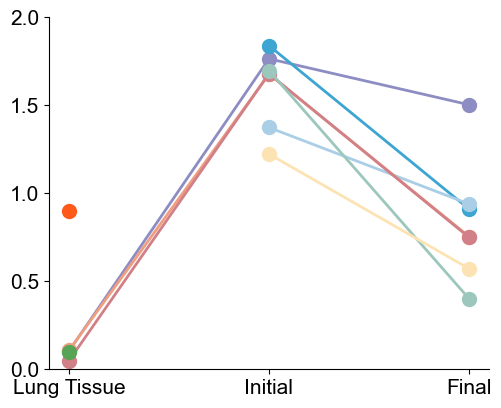

Condition: Aged control, Protocol Negative Fraction between WL


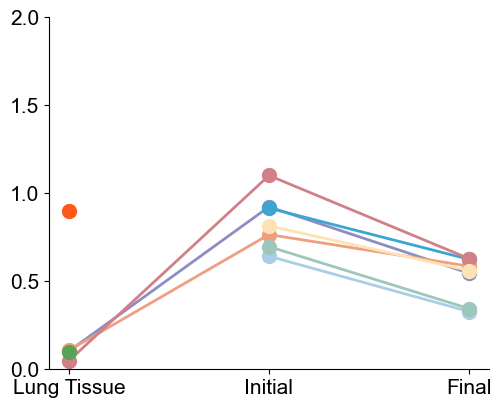

Condition: Aged control, Protocol Outgrowth between WL


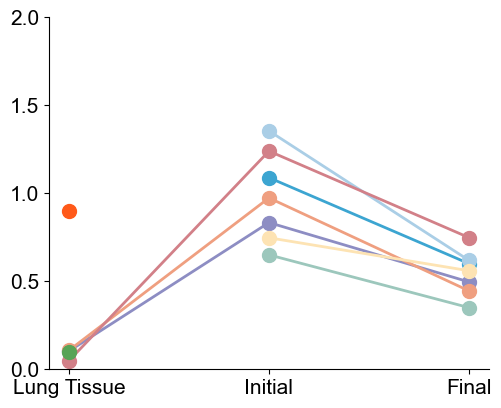

Condition: IPF upper lobe, Protocol WLCS between WL


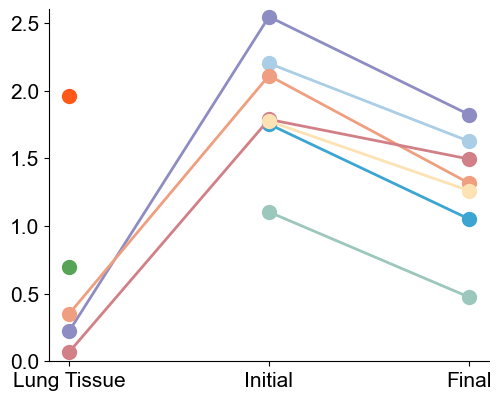

Condition: IPF upper lobe, Protocol Negative Fraction between WL


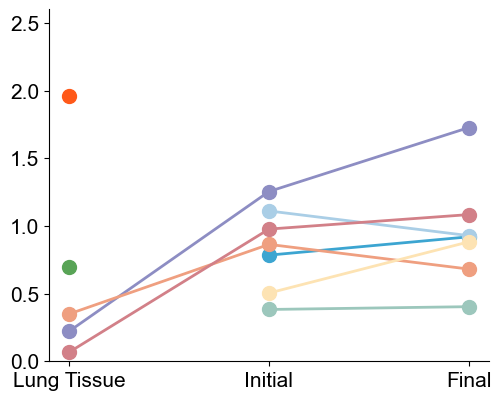

Condition: IPF upper lobe, Protocol Outgrowth between WL


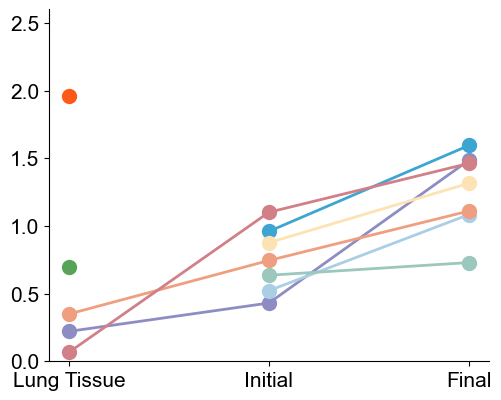

Condition: IPF lower lobe, Protocol WLCS between WL


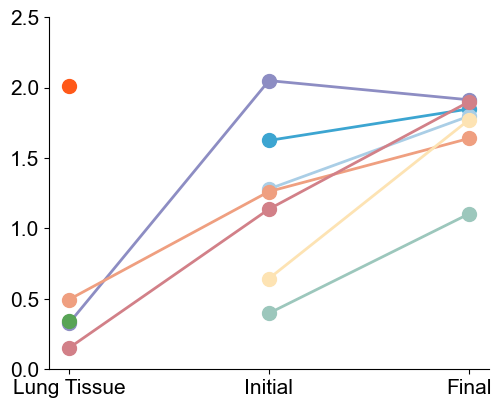

Condition: IPF lower lobe, Protocol Negative Fraction between WL


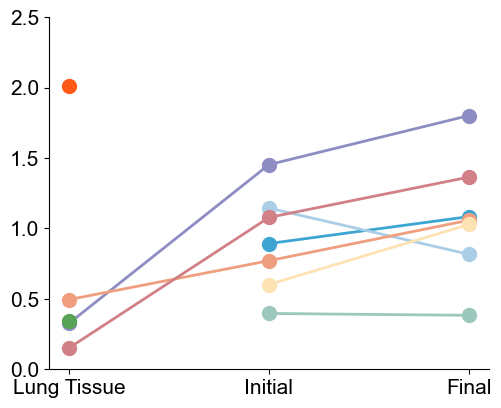

In [52]:
conditions_scale = [2, 2.5, 2.5]


with plt.rc_context({'font.size': 15, 'legend.fontsize': 15}):
    legend_saved = False
    
    conditions = ['Aged control', 'IPF upper lobe', 'IPF lower lobe']
    conditions_scale = [2, 2.6, 2.5]
    
    for cond, y_max in zip(conditions, conditions_scale):
        cond_adata = c_adata[c_adata.obs['Condition'] == cond].copy()
        for pro in protocols:
            if pro not in cond_adata.obs['Protocol'].unique():
                continue
            else:
                print(f"Condition: {cond}, Protocol {pro} between WL")
                pro_adata = cond_adata[cond_adata.obs['Protocol'].isin(['Lung Tissue', pro])].copy()
                cell_types = ['Adventitial', 'Alveolar 1', 'Alveolar 2', 'Inflammatory', 'SMCs', 'CTHRC1+', 'Peribronchial', 'Senescence-like', 'Proliferating']
                
                # Define colors for each cell type
                colors = {
                    "Alveolar 1": "#3CA5D1",
                    "Alveolar 2": "#aacee6",
                    "Adventitial": "#8D8DC3",
                    "Inflammatory": '#EF9F80',
                    "SMCs": "#D28088",
                    "Senescence-like": "#9CC7BC",
                    "Proliferating": "#FDE3B3",
                    "CTHRC1+": "#FF5919",
                    "Peribronchial": "#58A456",
                }
                
                fig, ax = plt.subplots(figsize=(5, 4))
                
                for ct in cell_types:
                    subset = pro_adata[pro_adata.obs['annotation'] == ct]
                    passages = ['Lung Tissue', 'Initial', 'Final']
                    
                    means = []
                    for p in passages:
                        p_subset = subset[subset.obs['Passage'] == p]
                        if len(p_subset) > 0:
                            mean_val = p_subset.X[:, pro_adata.var_names.get_loc('CTHRC1')].mean()
                            means.append(mean_val)
                        else:
                            means.append(np.nan)
                    
                    ax.plot(passages, means, marker='o', label=ct, color=colors[ct], linewidth=2,
                           markersize=10)
                
                # ax.set_ylabel('CTHRC1 Expression')
                
                # Set y-axis limits based on condition-specific scale
                ax.set_ylim(0, y_max)
                ax.yaxis.set_major_locator(ticker.MultipleLocator(0.5))

                ax.spines['top'].set_visible(False)
                ax.spines['right'].set_visible(False)

                
                # Get legend handles and labels (only save once)
                if not legend_saved:
                    handles, labels = ax.get_legend_handles_labels()
                
                fig.subplots_adjust(left=0.1, right=0.98, top=0.98, bottom=0.10)
                plt.savefig(f'{figure_save_path}/CTHRC1_curve_{cond}_{pro}.pdf')
                plt.show()
                
                # Save legend only once
                if not legend_saved:
                    fig_legend = plt.figure(figsize=(3, 3))
                    ax_legend = fig_legend.add_subplot(111)
                    ax_legend.axis('off')
                    ax_legend.legend(handles, labels, loc='center', fontsize=15, frameon=False)
                    
                    fig_legend.savefig(f'{figure_save_path}/CTHRC1_curve_legend.pdf', 
                                       bbox_inches='tight')
                    plt.close(fig_legend)
                    legend_saved = True
